In [1]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.datasets import make_classification
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import seaborn as sns

In [2]:
N = 100
X12, y = make_classification(n_samples=N, n_classes=2, n_features=2, n_redundant=0, shift=10)

In [3]:
X3 = np.random.default_rng().choice(['a', 'b', 'c'], size=N)

In [4]:
N_missing = 5
idx_missing = np.random.default_rng().choice(range(N), size=N_missing, replace=False)
X12[idx_missing, 0] = np.nan
X12[0, 0] = np.nan

In [5]:
df = pd.DataFrame(columns=['X1', 'X2'], data=X12)
df['X3'] = X3
df['y'] = y
display(df.head(10))
df.info()

,X1,X2,X3,y
0,NaN,9.131342,a,0
1,11.577049,10.655776,c,1
2,8.572909,8.726714,a,0
3,9.481528,11.787095,b,1
4,11.196907,9.345512,c,0
5,8.163560,11.109887,b,1
6,10.115209,10.301608,b,1
7,10.255230,10.917505,b,1
8,7.922913,11.513576,a,1
9,8.161945,11.616178,c,1


<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X1      94 non-null     float64
 1   X2      100 non-null    float64
 2   X3      100 non-null    str    
 3   y       100 non-null    int64  
dtypes: float64(2), int64(1), str(1)
memory usage: 3.3 KB


<Axes: xlabel='X1', ylabel='X2'>

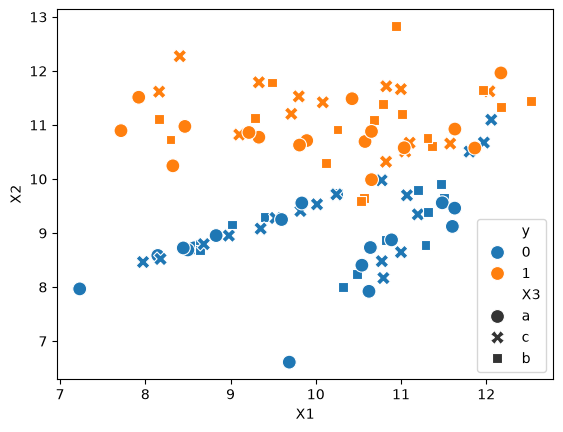

In [6]:
sns.scatterplot(data=df, x='X1', y='X2', hue='y', style='X3', s=100)

In [7]:
num_imputer = SimpleImputer(strategy='mean')
scaler = StandardScaler()
num_preprocessor = make_pipeline(num_imputer, scaler)

cat_imputer = SimpleImputer(strategy='most_frequent')
encoder = OneHotEncoder(drop='first')
cat_preprocessor = make_pipeline(cat_imputer, encoder)

preprocessor = ColumnTransformer([
    ('numerical', num_preprocessor, ['X1', 'X2']),
    ('categorical', cat_preprocessor, ['X3'])
])

In [8]:
X, y = df.drop(['y'], axis=1), df.y
X

,X1,X2,X3
0,NaN,9.131342,a
1,11.577049,10.655776,c
2,8.572909,8.726714,a
3,9.481528,11.787095,b
4,11.196907,9.345512,c
...,...,...,...
95,8.445346,8.724131,a
96,8.323183,10.244423,a
97,8.830563,8.953399,a
98,9.836103,9.556727,a


In [9]:
preprocessor.fit(X)
print(preprocessor.transform(X))

[[ 0.         -0.78220511  0.          0.        ]
 [ 1.15679066  0.4872539   0.          1.        ]
 [-1.33204476 -1.1191555   0.          0.        ]
 [-0.5792826   1.42934922  1.          0.        ]
 [ 0.84185528 -0.60385686  0.          1.        ]
 [-1.67117776  0.86541084  1.          0.        ]
 [-0.05429752  0.19232328  1.          0.        ]
 [ 0.06170514  0.70520608  1.          0.        ]
 [-1.87054634  1.20157932  0.          0.        ]
 [-1.6725156   1.28702017  0.          1.        ]
 [-0.23771603  0.53374533  0.          0.        ]
 [-1.27313021 -1.05787653  1.          0.        ]
 [-0.64855412 -0.64127568  1.          0.        ]
 [-0.54088863 -0.65881557  0.          1.        ]
 [ 1.2022961   0.71137209  0.          0.        ]
 [-1.82909358 -1.33817162  0.          1.        ]
 [ 0.32868273  0.51934742  0.          0.        ]
 [ 1.10017411 -0.34716369  1.          0.        ]
 [ 0.53038209 -1.00055127  1.          0.        ]
 [ 0.11404612 -1.72437009  1.  

In [10]:
model = LogisticRegression()
pipeline = make_pipeline(preprocessor, model)

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, stratify=y)

In [12]:
pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['X1','X2','X3']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwer

In [13]:
y_pred = pipeline.predict(X_test)
accuracy_score(y_test, y_pred)

0.9